# Multiscale Bootstrap for Three-Layer Causal Discovery

This notebook applies the multiscale bootstrap to the three-layer causal discovery in `Example_to_perform_causal_discovery_on_data_with_discrete_variables.ipynb`. The variables are classified into exogenous, endogenous and sink variables, and the exogenous and sink variables may be discrete.

## Theory

Variables are classified into three layers: exogenous variables, endogenous variables, and a sink variable. The exogenous variables and the sink variable may be discrete, whereas the endogenous variables must be continuous. The causal graph is estimated in the following steps (see the original notebook for the details).

1. Remove the effects of the exogenous variables from the other variables by linear regression and record the coefficients $ W_{endogenous} $.
2. Estimate the adjacency matrix $ B'_{endogenous} $ of the endogenous variables by DirectLiNGAM with the data whose exogenous effects are removed.
3. Estimate the coefficients $ W_{sink} $ from the endogenous variables to the sink variable by logistic regression.
4. Stack $ B_{exogenous} $, $ W_{endogenous} $, $ B'_{endogenous} $ and $ W_{sink} $ into one adjacency matrix $ \hat{B} $. $ B_{exogenous} $ has NaN in its off-diagonal elements, which means that the exogenous variables may have hidden common causes.

<img src="images/example_to_analyze_data_with_discrete_variables6.png" style="width:60%">

## Import and settings

In this example, we need to import `numpy`, `pandas`, `scipy`, and `graphviz` in addition to `lingam`. We also import `sklearn.utils.check_array`, which is used by the model for the sink variable.

In [1]:
import os
import requests

import numpy as np
import pandas as pd
from scipy.special import expit
import graphviz as gv
from IPython.display import display

import lingam
from lingam.utils import make_dot
from lingam.utils import remove_effect
from sklearn.utils import check_array

print([np.__version__, pd.__version__, gv.__version__, lingam.__version__])

np.set_printoptions(precision=3, suppress=True)
np.random.seed(0)

['2.2.6', '3.0.6', '0.21', '1.13.0']


### Source code of adaptive logistic regression

The sink variable is a discrete variable, so we use adaptive logistic regression of [ada_logistic_reg](https://github.com/cdt15/ada_logistic_reg) as the model of the sink variable. It prunes the coefficients to exactly zero, which is needed to get a sparse $ W_{sink} $. The R and glmnet packages must be installed manually. The source code is downloaded only if the directory `ada_log_reg` does not exist.

In [2]:
def _get_code(url, dirname="."):
    res = requests.get(url)
    if res.status_code != 200:
        raise RuntimeError("Couldn't get a source code.")
    
    with open(dirname + os.sep + url.split("/")[-1], "w") as f:
        f.write(res.text)

# destinaiton of downloaded source code
dirname = "ada_log_reg"

# download required source code
if not os.path.isdir(dirname):
    os.mkdir(dirname)
    base_url = "https://raw.githubusercontent.com/cdt15/ada_logistic_reg/refs/heads/main/ada_logistic_reg/"
    for filename in ["_adaptive_logistic_regression.py", "adaptive_logistic_regression.r", "__init__.py"]:
        _get_code(base_url + filename, dirname=dirname)

from ada_log_reg import predict_adaptive_logistic_regression

# check that dounwloaded source code works properly
try:
    X = np.random.uniform(size=(2, 100))
    y = expit(2 * X[0] - X[1]) >= np.random.uniform(size=100)
    X = np.vstack([X, y]).T
    predict_adaptive_logistic_regression(X, [0, 1], 2)
except:
    raise RuntimeError("Check that the R and glmnet packages are installed and that the path to the Rscript is set correctly.")

# define an interface like scikit-learn
class AdaptiveLogisticRegression:

    def fit(self, X, y):
        X = check_array(X)
        y = check_array(y, ensure_2d=False, dtype=int)
        
        X_ = np.concatenate([X, y.reshape(-1, 1)], axis=1)
        
        predictors = np.arange(len(X.T))
        target = X_.shape[1] - 1
        
        coef = predict_adaptive_logistic_regression(X_, predictors, target)
        
        self.coef_ = coef

### Source code of multiscale bootstrap

We use [pyscaleboot](https://github.com/cdt15/multiscale-bootstrap) to run the multiscale bootstrap. It runs the bootstrap with several resample sizes and computes the AU / SI p-values with the R package `scaleboot`. The R and scaleboot packages must be installed manually. The source code is downloaded only if the directory `pyscaleboot` does not exist.

In [3]:
# destination of downloaded source code
dirname = "pyscaleboot"

# download required source code
if not os.path.isdir(dirname):
    os.mkdir(dirname)
    base_url = "https://raw.githubusercontent.com/cdt15/multiscale-bootstrap/refs/heads/main/pyscaleboot/"
    for filename in ["__init__.py", "_bootstrap.py", "_hypotheses.py", "_scaleboot.py", "scaleboot.r"]:
        _get_code(base_url + filename, dirname=dirname)

from pyscaleboot import (
    MultiScaleBootstrap,
    EdgeHypothesis,
    GraphHypothesis,
    RScalebootClient,
    build_scaleboot_input,
)

# check that downloaded source code works properly
# a separate generator keeps the global random state used for the test data unchanged
rng = np.random.default_rng(0)
X = rng.uniform(size=(100, 2))
X[:, 1] += 2 * X[:, 0]
result = MultiScaleBootstrap(lingam.DirectLiNGAM(), n_bootstrap=5).bootstrap(X)
assert all(scale.n_failure == 0 for scale in result.scales)

edge_bp_long = EdgeHypothesis().extract(result)
graph_bp_long, _ = GraphHypothesis().extract(result)
bp, scales = build_scaleboot_input(pd.concat([edge_bp_long, graph_bp_long], ignore_index=True))

try:
    RScalebootClient().fit(bp, scales, models=("poly.1",))
except:
    raise RuntimeError("Check that the R and scaleboot packages are installed and that the path to the Rscript is set correctly.")

## Test data

### Adjacency matrix

In [4]:
m = np.array([
    [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.5215, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.8635, 0.2685, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    [0.5205, 0.0000, 0.0000, 0.2135, 0.4555, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.0000, 0.0000, 0.9800, 0.0000, 0.0000, 0.0000, 0.0000],
    [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.4415, 0.6925, 0.0000],
])

names = [f"x{i + 1}" for i in range(len(m))]
m = pd.DataFrame(m, columns=names, index=names)

m

,x1,x2,x3,x4,x5,x6,x7,x8
x1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
x2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
x3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
x4,0.0000,0.5215,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
x5,0.0000,0.8635,0.2685,0.0000,0.0000,0.0000,0.0000,0.0
x6,0.5205,0.0000,0.0000,0.2135,0.4555,0.0000,0.0000,0.0
x7,0.0000,0.0000,0.0000,0.9800,0.0000,0.0000,0.0000,0.0
x8,0.0000,0.0000,0.0000,0.0000,0.0000,0.4415,0.6925,0.0


This adjacency matrix is drawn as a following causal graph:

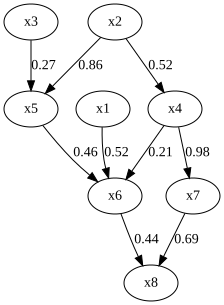

In [5]:
make_dot(m, lower_limit=0, labels=m.columns.tolist())

### Generate test data

A test data is generated according to the adjacency matrix and x1 and x8 are generated as discrete variables. The values of that discrete variables are 0 or 1.

In [6]:
# settings
n_sample = 1000
discrete_indices = [0, 7]

# initialize
X = np.zeros((len(m), n_sample))

# generate test data according to m
for i in range(len(m)):
    if i not in discrete_indices:
        X[i] = m.iloc[i] @ X + np.random.uniform(-1.732, 1.732, size=n_sample)
    else:
        X[i] = (expit(m.iloc[i] @ X) >= np.random.uniform(0, 1, size=n_sample)).astype(int)
X = pd.DataFrame(X.T, columns=names)

# convert types of continuous variables to float, types of discrete variables to int
dtypes = {}
for i, name in enumerate(names):
    dtypes[name] = int if i in discrete_indices else float
X = X.astype(dtypes)

Types of test data are as follows:

In [7]:
X.dtypes

x1      int64
x2    float64
x3    float64
x4    float64
x5    float64
x6    float64
x7    float64
x8      int64
dtype: object

### Classify test data variables into three subsets

We classify test data variables into three subsets: exogenous variables, endogenous variables, and sink variables.

In [8]:
exog_var_names = ["x1", "x2", "x3"]
endog_var_names = ["x4", "x5", "x6", "x7"]
sink_var_name = "x8"

exog_indices = [names.index(v) for v in exog_var_names]
endog_indices = [names.index(v) for v in endog_var_names]
sink_index = names.index(sink_var_name)

The causal graph is as follows:

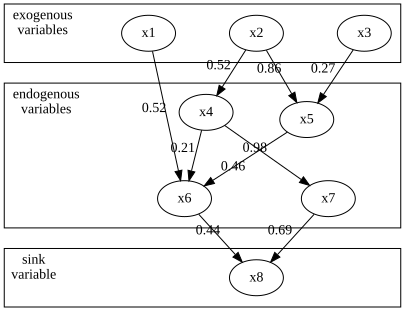

In [9]:
def display_graph(m, exog_var_names, endog_var_names, sink_var_name):
    g = gv.Digraph(engine="neato", graph_attr={"splines":"true"})

    cluster_names = ["exogenous", "endogenous", "sink"]

    node_kws = {
        "x1": {"pos": "0,0!"},
        "x2": {"pos": "1.5,0!"},
        "x3": {"pos": "3.0,0!"},
        "x4": {"pos": "0.8,-1.1!"},
        "x5": {"pos": "2.2,-1.2!"},
        "x6": {"pos": "0.5,-2.3!"},
        "x7": {"pos": "2.5,-2.3!"},
        "x8": {"pos": "1.5,-3.4!"},
    }

    dummy_node_kws = {
        "exogenous": [
            {"pos":"-2,0.4!", "style":"invis", "fixedsize":"true", "width":"0", "height":"0"},
            {"pos":"3.5,-0.4!", "style":"invis", "fixedsize":"true", "width":"0", "height":"0"},
        ],
        "endogenous": [
            {"pos":"-2,-0.7!", "style":"invis", "fixedsize":"true", "width":"0", "height":"0"},
            {"pos":"3.5,-2.7!", "style":"invis", "fixedsize":"true", "width":"0", "height":"0"},
        ],
        "sink": [
            {"pos":"-2,-3.0!", "style":"invis", "fixedsize":"true", "width":"0", "height":"0"},
            {"pos":"3.5,-3.8!", "style":"invis", "fixedsize":"true", "width":"0", "height":"0"},
        ]
    }

    # add nodes
    for cluster_name, var_names in zip(cluster_names, [exog_var_names, endog_var_names, [sink_var_name]]):
        # make subgraph
        with g.subgraph(name=f"cluster_{cluster_name}", graph_attr={"margin":"4,4!"}) as sub:
            for var_name in var_names:
                kw = {} if var_name not in node_kws.keys() else node_kws[var_name]
                sub.node(var_name, var_name, **kw)
            s = "" if cluster_name == "sink" else "s"
            sub.attr(label=f"{cluster_name}\nvariable" + s, labeljust="l")

            # dummies
            sub.node(cluster_name + "_lu", "", **dummy_node_kws[cluster_name][0])
            sub.node(cluster_name + "_rl", "", **dummy_node_kws[cluster_name][1])

    # add edges
    for to_name, coefs in m.iterrows():
        for from_name, coef in coefs.items():
            if np.isclose(coef, 0):
                continue

            g.edge(from_name, to_name, label=f"{coef:.2f}")

    display(g)

display_graph(m, exog_var_names, endog_var_names, sink_var_name)

## Three-layer model

`MultiScaleBootstrap` accepts any model that has `fit(X)` and `adjacency_matrix_`. We therefore put the three steps of the analysis into one class `ThreeLayerLiNGAM`. `fit` removes the effects of the exogenous variables, runs `cd_model` (DirectLiNGAM) on the endogenous variables, fits `sink_model` for the sink variable, and stacks the results into one adjacency matrix of all the variables.

In [10]:
class ThreeLayerLiNGAM:
    """Three-layer causal discovery with exogenous, endogenous and sink variables.

    Parameters
    ----------
    exog_indices, endog_indices : list of int
        Column indices of the exogenous and the endogenous variables.
    sink_index : int
        Column index of the sink variable (a discrete variable).
    cd_model : object, optional
        LiNGAM model for the endogenous variables. Default is DirectLiNGAM.
    sink_model : object, optional
        Model with fit(X, y) and coef_ for the sink variable.
        Default is AdaptiveLogisticRegression.
    """

    def __init__(self, exog_indices, endog_indices, sink_index, cd_model=None, sink_model=None):
        self.exog_indices = list(exog_indices)
        self.endog_indices = list(endog_indices)
        self.sink_index = sink_index
        self.cd_model = lingam.DirectLiNGAM() if cd_model is None else cd_model
        self.sink_model = AdaptiveLogisticRegression() if sink_model is None else sink_model

    def fit(self, X):
        X = check_array(X)
        n_features = X.shape[1]

        # 1. remove the effects of the exogenous variables by linear regression
        X_removed_exog, W_endog = remove_effect(X, self.exog_indices, return_coefs=True)
        X_endog = X_removed_exog[:, self.endog_indices]

        # 2. causal discovery on the endogenous variables
        self.cd_model.fit(X_endog)

        # 3. model of the sink variable
        self.sink_model.fit(X_endog, X[:, self.sink_index])

        # 4. stack the results into one adjacency matrix (adjacency[to, from])
        adjacency = np.zeros((n_features, n_features))
        for i in self.exog_indices:
            for j in self.exog_indices:
                if i != j:
                    adjacency[i, j] = np.nan  # hidden common causes between exogenous variables
        for to in self.endog_indices:
            adjacency[to, self.exog_indices] = W_endog[to]
        adjacency[np.ix_(self.endog_indices, self.endog_indices)] = self.cd_model.adjacency_matrix_
        adjacency[self.sink_index, self.endog_indices] = np.ravel(self.sink_model.coef_)

        self.adjacency_matrix_ = adjacency
        return self

## Causal discovery

To run causal discovery, we create a `ThreeLayerLiNGAM` object and call the `fit` method. Using the `adjacency_matrix_` property, we can see the adjacency matrix, where NaN means hidden common causes.

In [11]:
three_layer_model = ThreeLayerLiNGAM(exog_indices, endog_indices, sink_index)
three_layer_model.fit(X)

adj = pd.DataFrame(three_layer_model.adjacency_matrix_, index=names, columns=names)
adj

,x1,x2,x3,x4,x5,x6,x7,x8
x1,0.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.0
x2,NaN,0.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.0
x3,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
x4,0.091775,0.495306,0.060782,0.000000,0.000000,0.000000,0.000000,0.0
x5,0.074820,0.818981,0.236677,0.000000,0.000000,0.000000,0.000000,0.0
x6,0.578107,0.528316,0.133799,0.185069,0.449379,0.000000,0.000000,0.0
x7,0.105362,0.483584,0.033524,0.951487,0.000000,0.000000,0.000000,0.0
x8,0.000000,0.000000,0.000000,0.000000,0.000000,0.461117,0.697899,0.0


The causal graph is as follows:

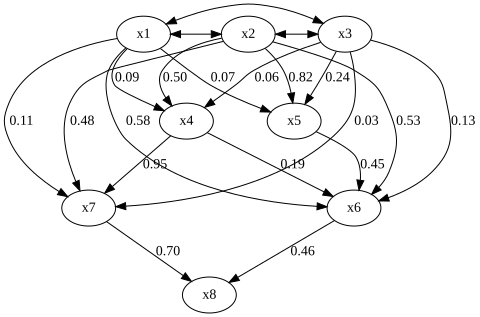

In [12]:
make_dot(adj, labels=adj.columns.tolist(), lower_limit=0.0)

## Multiscale Bootstrap

The ordinary bootstrap estimates the bootstrap probability (BP) of a hypothesis, such as the existence of an edge, with resamples of the original size `n`. The multiscale bootstrap repeats it with several resample sizes `n'` and observes how BP changes with the scale `sa = n / n'`. From this change, the R package `scaleboot` computes the AU (approximately unbiased) p-value, which corrects the bias of BP, and the SI (selective inference) p-value, which takes into account that the hypothesis is selected from the data.

We use the `pyscaleboot` package in the `examples` directory in four steps: `MultiScaleBootstrap` runs the bootstrap on several scales, `EdgeHypothesis` and `GraphHypothesis` extract hypotheses and their BP, `RScalebootClient` converts BP to AU / SI p-values, and then we read the results. `Rscript` and the R package `scaleboot` are required. Here the multiscale bootstrap is applied to the whole three-layer analysis.

### Settings

The package's public API has already been imported and checked in the setup cell above. The following settings configure the multiscale bootstrap.

`SCALE_RATIOS` are the ratios `n' / n` of the resample sizes, and `N_BOOTSTRAP` is the number of resamples for each scale. `MIN_CAUSAL_EFFECT` is the minimum absolute coefficient regarded as a directed edge, and `SCALEBOOT_MODELS` are the candidate models of `scaleboot`.

The bootstrap is run once. AU / SI p-values are then calculated from the resulting BP table using the configured `scaleboot` options.

In [13]:
SCALE_RATIOS = (0.5, 0.7, 1.0, 1.4, 2.0)  # n' / n
N_BOOTSTRAP = 1000  # number of resamples for each scale
MIN_CAUSAL_EFFECT = 0.01
SCALEBOOT_MODELS = ("poly.1", "poly.2", "poly.3", "sing.3", "sphe.3")  # default of scaleboot
# options for scaleboot; the bootstrap itself is run only once
SCALEBOOT_CONDITIONS = {
    "ave": dict(models=SCALEBOOT_MODELS, select="average"),
    "best": dict(models=SCALEBOOT_MODELS, select="best"),
    "poly1": dict(models=("poly.1",), select="average"),
}
RANDOM_STATE = 0

### Saved bootstrap result

The bootstrap is the most time-consuming part, so its result (`MultiScaleBootstrapResult`) is saved in a pickle file, and the saved file is loaded instead of running the bootstrap again when this notebook is run again. The file name is made from the algorithm, the number of resamples `N_BOOTSTRAP` and `SCALE_RATIOS`. Only `msb_result` is saved in the file, so the random seed and the data are not checked when the file is loaded; after changing them, delete the file or set `FORCE_RERUN = True` below.

In [14]:
import os
import pickle

ALGORITHM = "ThreeLayerLiNGAM"
RESULT_DIR = "."  # directory of the saved bootstrap results


def result_file_path():
    ratio_text = "-".join(f"{ratio:g}" for ratio in SCALE_RATIOS)
    name = f"MultiscaleBootstrap-{ALGORITHM}_boot{N_BOOTSTRAP}_ratio{ratio_text}_msb_result.pkl"
    return os.path.join(RESULT_DIR, name)


def save_msb_result(path, msb_result):
    with open(path, "wb") as f:
        pickle.dump(msb_result, f)


def load_msb_result(path):
    with open(path, "rb") as f:
        return pickle.load(f)

### Run multiscale bootstrap (or load the saved result)

If the file `result_file_path()` exists, it is loaded and the bootstrap is not run. Otherwise, the bootstrap is run with `MultiScaleBootstrap` and the result is saved in that file. Set `FORCE_RERUN = True` to run the bootstrap again and overwrite the file.

`MultiScaleBootstrap` takes an unfitted model that has `fit(X)` and `adjacency_matrix_`, so any LiNGAM model can be used. Here we use `ThreeLayerLiNGAM`, so all three steps of the analysis, including the removal of the exogenous effects, are re-estimated on every resample. The same model is refitted on every resample, and for each scale `bootstrap` draws `n' = round(scale_ratio * n)` rows with replacement. The result is a `MultiScaleBootstrapResult` that keeps the raw adjacency matrices of all resamples.

In [15]:
variable_names = X.columns.tolist()

FORCE_RERUN = False  # True: run the bootstrap again and overwrite the saved file

path = result_file_path()
if os.path.exists(path) and not FORCE_RERUN:
    msb_result = load_msb_result(path)
    print(f"Loaded the saved result: {path}")
else:
    msb = MultiScaleBootstrap(
        ThreeLayerLiNGAM(exog_indices, endog_indices, sink_index),
        scale_ratios=SCALE_RATIOS,
        n_bootstrap=N_BOOTSTRAP,
        random_state=RANDOM_STATE,
    )
    msb_result = msb.bootstrap(X, variable_names=variable_names)
    save_msb_result(path, msb_result)
    print(f"Ran the bootstrap and saved the result: {path}")

Loaded the saved result: .\MultiscaleBootstrap-ThreeLayerLiNGAM_boot1000_ratio0.5-0.7-1-1.4-2_msb_result.pkl


`scale_summary()` shows the resample size `n_prime`, the scale `sa = n / n_prime`, and the numbers of successful and failed fits of each scale. A failed fit does not stop the bootstrap and is recorded in `msb_result.scales[i].failures`; BP is calculated from the successful fits only.

In [16]:
msb_result.scale_summary()

,scale_index,scale_ratio,n,n_prime,sa,n_bootstrap,n_success,n_failure
0,0,0.5,1000,500,2.000000,1000,1000,0
1,1,0.7,1000,700,1.428571,1000,1000,0
2,2,1.0,1000,1000,1.000000,1000,1000,0
3,3,1.4,1000,1400,0.714286,1000,1000,0
4,4,2.0,1000,2000,0.500000,1000,1000,0


### Extract hypotheses

`EdgeHypothesis` extracts the directed edges (`edge:from->to`), and `GraphHypothesis` extracts the whole graphs (`graph:<hash>`). Variables in `hypothesis_id` are the column indices. Both return BP in the long format `bp_long` with one row per hypothesis and scale. `MIN_CAUSAL_EFFECT` is applied here, so it can be changed without rerunning the bootstrap. The three-layer model estimates only the edges from the exogenous to the endogenous variables, between the endogenous variables, and from the endogenous variables to the sink variable, so the other edges (BP is always 0) are dropped. The bidirected edges between the exogenous variables are an assumption of the model, not an estimation result, so they are not tested either; they remain only in the state matrices of the graph hypotheses.

In [17]:
edge_bp_long = EdgeHypothesis().extract(
    msb_result,
    min_causal_effect=MIN_CAUSAL_EFFECT,
)
# keep only the edges that the three-layer model can estimate
allowed_edge_ids = (
    {f"edge:{i}->{j}" for i in exog_indices for j in endog_indices}  # exogenous -> endogenous
    | {f"edge:{i}->{j}" for i in endog_indices for j in endog_indices if i != j}  # endogenous -> endogenous
    | {f"edge:{i}->{sink_index}" for i in endog_indices}  # endogenous -> sink
)
edge_bp_long = edge_bp_long[edge_bp_long["hypothesis_id"].isin(allowed_edge_ids)]
graph_bp_long, graph_states = GraphHypothesis().extract(
    msb_result,
    min_causal_effect=MIN_CAUSAL_EFFECT,
)
bp_long = pd.concat([edge_bp_long, graph_bp_long], ignore_index=True)
print(f"{len(bp_long)} rows, {bp_long['hypothesis_id'].nunique()} hypotheses")
bp_long.head()

860 rows, 172 hypotheses


,hypothesis_id,scale_index,sa,nb,bp
0,edge:0->3,0,2.0,1000,0.948
1,edge:1->3,0,2.0,1000,1.000
2,edge:2->3,0,2.0,1000,0.932
3,edge:4->3,0,2.0,1000,0.009
4,edge:5->3,0,2.0,1000,0.000


The BP of each edge at each scale is shown below. The column `sa = 1` is the ordinary bootstrap probability, and the AU p-value takes into account how BP changes with `sa`.

In [18]:
edge_bp_long.pivot(index="hypothesis_id", columns="sa", values="bp")

sa,0.500000,0.714286,1.000000,1.428571,2.000000
hypothesis_id,,,,,
edge:0->3,0.972,0.971,0.962,0.937,0.948
edge:0->4,0.968,0.944,0.929,0.930,0.938
edge:0->5,1.000,1.000,1.000,1.000,1.000
edge:0->6,0.973,0.956,0.957,0.957,0.950
edge:1->3,1.000,1.000,1.000,1.000,1.000
edge:1->4,1.000,1.000,1.000,1.000,1.000
edge:1->5,1.000,1.000,1.000,1.000,1.000
edge:1->6,1.000,1.000,1.000,1.000,1.000
edge:2->3,0.989,0.988,0.974,0.946,0.932


### Calculate AU / SI p-values

`build_scaleboot_input` pivots `bp_long` into the two tables required by `scaleboot::sbfit`: `bp` (hypotheses × scales) and `scales` (the number of successful resamples `nb` and the scale `sa` of each column of `bp`). All hypotheses in `bp_long` are passed, so filter `bp_long` beforehand to restrict the hypotheses.

In [19]:
bp, scales = build_scaleboot_input(bp_long)
print(f"Number of hypotheses: {len(bp)}")
scales

Number of hypotheses: 172


,nb,sa
scale_index,,
0,1000,2.000000
1,1000,1.428571
2,1000,1.000000
3,1000,0.714286
4,1000,0.500000


`RScalebootClient().fit` runs the bundled `scaleboot.r` with `Rscript` and returns one row per hypothesis: the AU p-value (`au_pvalue`, `au_se`), the SI p-value (`si_pvalue`, `si_se`), the selected model, and its coefficients `beta0` and `beta1`. `models` are the candidate models of `sbfit`, `k` and `sk` (default 3) are the orders of the AU and SI p-values, and `select` (`"average"` or `"best"`) specifies how the models are combined.

The same `bp` and `scales` are passed to `fit` using the configured `scaleboot` options. The results are stored in `scaleboot_frames`.

In [20]:
scaleboot_frames = {}
for condition, options in SCALEBOOT_CONDITIONS.items():
    scaleboot_frames[condition] = RScalebootClient().fit(
        bp, scales, models=options["models"], select=options["select"]
    )
    print(f"{condition}: {len(scaleboot_frames[condition])} hypotheses")

scaleboot_frames["best"].head()

ave: 172 hypotheses
best: 172 hypotheses
poly1: 172 hypotheses


,hypothesis_id,au_pvalue,au_se,si_pvalue,si_se,best_model,beta0,beta1
0,edge:0->3,0.714076,0.045017,0.599410,0.051146,poly.2,-1.129727,-0.564396
1,edge:0->4,0.914722,0.084826,0.804623,0.123985,poly.3,-0.994277,-0.488800
2,edge:0->5,1.000000,0.000000,1.000000,0.000000,raw,NaN,NaN
3,edge:0->6,0.626466,0.049689,0.503874,0.052849,poly.2,-1.006158,-0.683650
4,edge:1->3,1.000000,0.000000,1.000000,0.000000,raw,NaN,NaN


### Summarize the results

Each `final_results` table has one row per hypothesis. `bp_at_sa1` is BP at the scale closest to `sa = 1` (the ordinary bootstrap probability), and the other columns include the AU / SI p-values from `scaleboot`. `relation` shows the variable names of the edges and arcs.

In [21]:
def relation_label(hypothesis_id):
    """Convert 'edge:0->1' to 'x0->x1' (None for the graph hypotheses)."""
    kind, relation = hypothesis_id.split(":")
    if kind == "graph":
        return None
    sep = "<->" if kind == "arc" else "->"
    source, destination = (variable_names[int(v)] for v in relation.split(sep))
    return f"{source}{sep}{destination}"


bp_at_sa1 = (
    bp_long.assign(_sa_distance=lambda frame: (frame["sa"] - 1.0).abs())
    .sort_values(["hypothesis_id", "_sa_distance", "scale_index"])
    .drop_duplicates("hypothesis_id")
    .loc[:, ["hypothesis_id", "bp"]]
    .rename(columns={"bp": "bp_at_sa1"})
)


def summarize(scaleboot_frame):
    result = (
        bp_at_sa1.merge(scaleboot_frame, on="hypothesis_id", how="inner", validate="one_to_one")
        .assign(hypothesis_type=lambda frame: frame["hypothesis_id"].str.split(":").str[0])
        .sort_values(["hypothesis_type", "au_pvalue", "hypothesis_id"], ascending=[True, False, True])
        .reset_index(drop=True)
    )
    result["relation"] = result["hypothesis_id"].map(relation_label)
    return result


final_results = {condition: summarize(frame) for condition, frame in scaleboot_frames.items()}
conditions = list(final_results)

# the best-model column of the "best" condition: the model with the smallest AIC (independent of `select`)
final_results["best"].loc[
    final_results["best"]["hypothesis_type"] != "graph",
    ["relation", "bp_at_sa1", "au_pvalue", "au_se", "si_pvalue", "si_se", "best_model"],
]

,relation,bp_at_sa1,au_pvalue,au_se,si_pvalue,si_se,best_model
0,x1->x6,1.000,1.000000,0.000000,1.000000,0.000000,raw
1,x2->x4,1.000,1.000000,0.000000,1.000000,0.000000,raw
2,x2->x5,1.000,1.000000,0.000000,1.000000,0.000000,raw
3,x2->x6,1.000,1.000000,0.000000,1.000000,0.000000,raw
4,x2->x7,1.000,1.000000,0.000000,1.000000,0.000000,raw
5,x3->x5,1.000,1.000000,0.000000,1.000000,0.000000,raw
6,x4->x7,1.000,1.000000,0.000000,1.000000,0.000000,raw
7,x5->x6,1.000,1.000000,0.000000,1.000000,0.000000,raw
8,x7->x8,1.000,1.000000,0.000000,1.000000,0.000000,raw
9,x4->x6,0.998,0.999992,0.000017,0.999967,0.000064,poly.2


The AU / SI p-values for edge and arc hypotheses are shown side by side. Their standard errors (`au_se`, `si_se`) are available in `final_results[condition]`.

In [22]:
EDGE_COLUMNS = ["au_pvalue", "si_pvalue", "best_model"]

comparison = final_results["best"].loc[
    final_results["best"]["hypothesis_type"] != "graph", ["hypothesis_id", "relation", "bp_at_sa1"]
]
for condition, result in final_results.items():
    part = result[["hypothesis_id"] + EDGE_COLUMNS].rename(
        columns={c: f"{c}_{condition}" for c in EDGE_COLUMNS}
    )
    comparison = comparison.merge(part, on="hypothesis_id", validate="one_to_one")

comparison = (
    comparison.sort_values(["au_pvalue_best", "hypothesis_id"], ascending=[False, True])
    .reset_index(drop=True)
)
comparison[
    ["relation", "bp_at_sa1"] + [f"{c}_{condition}" for condition in conditions for c in EDGE_COLUMNS]
]

,relation,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,best_model_ave,au_pvalue_best,si_pvalue_best,best_model_best,au_pvalue_poly1,si_pvalue_poly1,best_model_poly1
0,x1->x6,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
1,x2->x4,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
2,x2->x5,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
3,x2->x6,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
4,x2->x7,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
5,x3->x5,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
6,x4->x7,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
7,x5->x6,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
8,x7->x8,1.000,1.000000,1.000000,raw,1.000000,1.000000,raw,1.000000,1.000000,raw
9,x4->x6,0.998,0.999101,0.998523,poly.2,0.999992,0.999967,poly.2,0.992223,0.984447,poly.1


Directed edges are drawn from the results. Each edge is labeled with its AU p-value. Edges with AU p-values of 0 or NaN (e.g. BP is 0 at all scales) are omitted. Labels use four decimal places because many AU p-values are close to 1 and would otherwise display as `1.00`.

Condition: ave


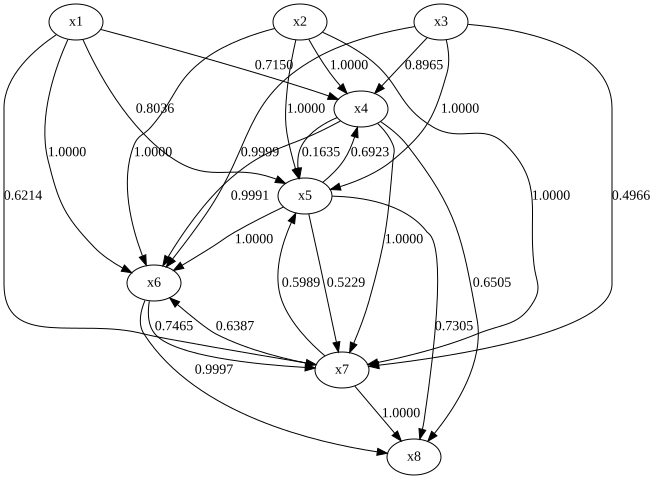

Condition: best


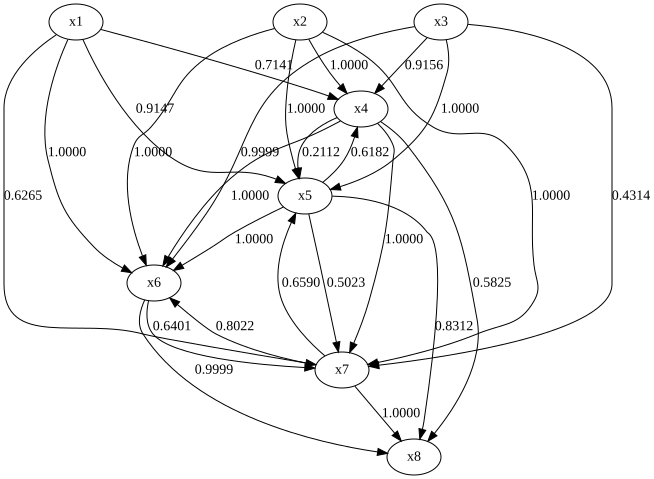

Condition: poly1


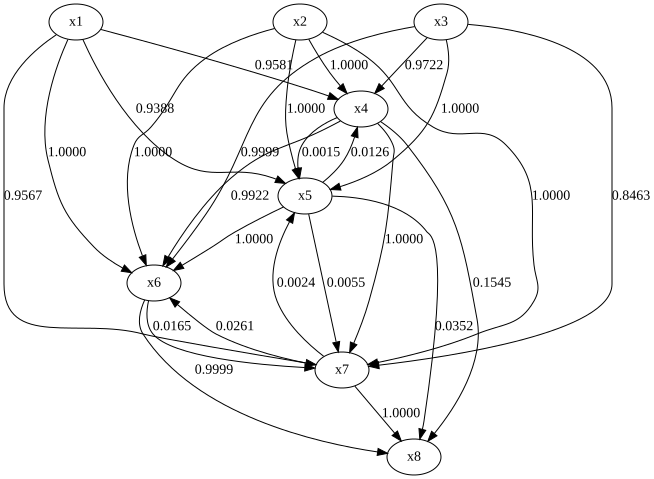

In [23]:
AU_LABEL_FORMAT = "{:.4f}"  # make_dot rounds to 2 digits, so 0.995 or more is shown as 1.00

for condition, result in final_results.items():
    g = gv.Digraph(engine="dot")
    for name in variable_names:
        g.node(name)
    for _, row in result[result["hypothesis_type"] == "edge"].iterrows():
        au_pvalue = row["au_pvalue"]
        if np.isnan(au_pvalue) or au_pvalue == 0:
            continue
        source, destination = map(int, row["hypothesis_id"].split(":")[1].split("->"))
        g.edge(variable_names[source], variable_names[destination], label=AU_LABEL_FORMAT.format(au_pvalue))
    print(f"Condition: {condition}")
    display(g)

### Whole-graph hypothesis

`graph_states` holds the edge-state matrix (0: no edge, 1: directed edge, 2: bidirected edge) of every graph hypothesis. `graph_comparison` presents BP and AU / SI p-values for each graph hypothesis. The edge labels `1.00` in the drawings are only placeholders of a directed edge, not coefficients.

In [24]:
GRAPH_COLUMNS = ["au_pvalue", "si_pvalue"]

graph_comparison = final_results["best"].loc[
    final_results["best"]["hypothesis_type"] == "graph", ["hypothesis_id", "bp_at_sa1"]
]
for condition, result in final_results.items():
    part = result[["hypothesis_id"] + GRAPH_COLUMNS].rename(
        columns={c: f"{c}_{condition}" for c in GRAPH_COLUMNS}
    )
    graph_comparison = graph_comparison.merge(part, on="hypothesis_id", validate="one_to_one")

graph_comparison = graph_comparison.sort_values(
    ["au_pvalue_best", "bp_at_sa1", "hypothesis_id"], ascending=[False, False, True]
).reset_index(drop=True)
print(f"{len(graph_comparison)} graph hypotheses")
graph_comparison

144 graph hypotheses


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:aa9029976469c0cd108a09c5179269cc11b1218d,0.010,0.806010,0.0,0.750462,0.0,0.009703,0.0
1,graph:6af82e21d4aa9bb0fd8e7e240177efd72a479446,0.099,0.616230,0.0,0.659349,0.0,0.106629,0.0
2,graph:6a4c141e2b81a4d7961b587b46bfece2ddae04ee,0.089,0.677037,0.0,0.648673,0.0,0.104438,0.0
3,graph:56c517409c05a665776bc0a142ae164c86f5d5ca,0.005,0.683308,0.0,0.632056,0.0,0.007144,0.0
4,graph:a6781d4eed4b608278b37a724889dabd5fb5918f,0.003,0.573855,0.0,0.623435,0.0,0.001943,0.0
...,...,...,...,...,...,...,...,...
139,graph:e6232437803634bd04df49cd3fa2240feb5e3006,0.000,0.000328,0.0,0.000008,0.0,0.000008,0.0
140,graph:e64fcfa4604c5872fff136194c7026083a5fd21a,0.000,0.000328,0.0,0.000008,0.0,0.000008,0.0
141,graph:e8bcf8d4dacb43b9d08bff336942522ccd2a7686,0.000,0.000328,0.0,0.000008,0.0,0.000008,0.0
142,graph:f746c4a5f6d2c83633d717342020f29064d407be,0.000,0.000328,0.0,0.000008,0.0,0.000008,0.0


`graph_comparison` is sorted by AU p-value. The top `TOP_GRAPH_COUNT` graphs are drawn in descending order of AU p-value, with BP at the scale closest to `sa = 1` and AU / SI p-values. A graph with a high AU p-value does not always have a high BP.

Condition: ave


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:aa9029976469c0cd108a09c5179269cc11b1218d,0.010,0.806010,0.0,0.750462,0.0,0.009703,0.0
7,graph:f0e73a1b119ac13697a3f05ba97b6a6e1abd881c,0.003,0.686267,0.0,0.486279,0.0,0.005388,0.0
3,graph:56c517409c05a665776bc0a142ae164c86f5d5ca,0.005,0.683308,0.0,0.632056,0.0,0.007144,0.0
2,graph:6a4c141e2b81a4d7961b587b46bfece2ddae04ee,0.089,0.677037,0.0,0.648673,0.0,0.104438,0.0
1,graph:6af82e21d4aa9bb0fd8e7e240177efd72a479446,0.099,0.616230,0.0,0.659349,0.0,0.106629,0.0


Rank 1: BP=0.010; ave: AU=0.806 SI=0.000, best: AU=0.750 SI=0.000, poly1: AU=0.010 SI=0.000


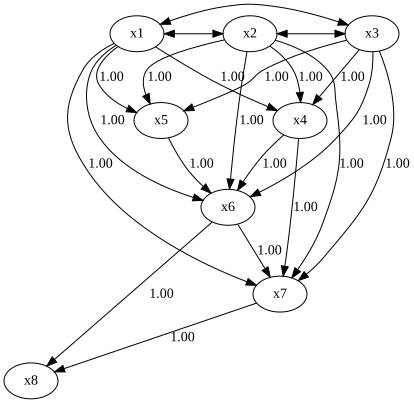

Rank 2: BP=0.003; ave: AU=0.686 SI=0.000, best: AU=0.486 SI=0.000, poly1: AU=0.005 SI=0.000


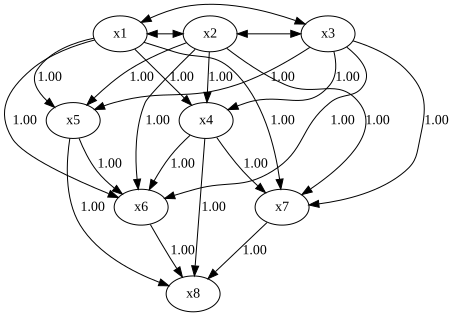

Rank 3: BP=0.005; ave: AU=0.683 SI=0.000, best: AU=0.632 SI=0.000, poly1: AU=0.007 SI=0.000


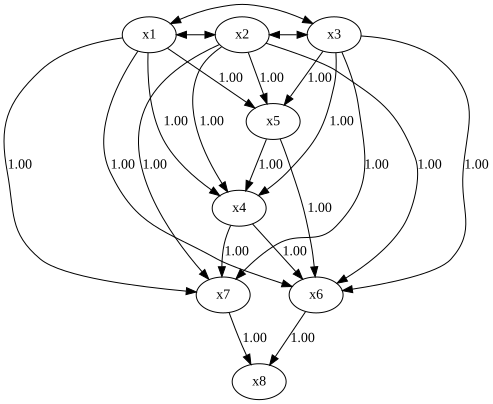

Rank 4: BP=0.089; ave: AU=0.677 SI=0.000, best: AU=0.649 SI=0.000, poly1: AU=0.104 SI=0.000


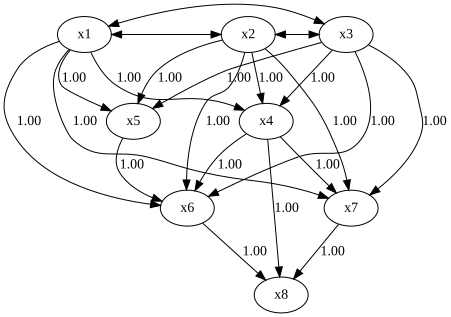

Rank 5: BP=0.099; ave: AU=0.616 SI=0.000, best: AU=0.659 SI=0.000, poly1: AU=0.107 SI=0.000


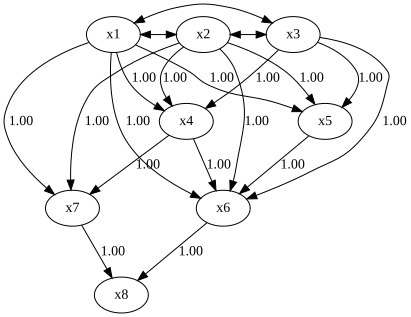

Condition: best


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:aa9029976469c0cd108a09c5179269cc11b1218d,0.010,0.806010,0.0,0.750462,0.0,0.009703,0.0
1,graph:6af82e21d4aa9bb0fd8e7e240177efd72a479446,0.099,0.616230,0.0,0.659349,0.0,0.106629,0.0
2,graph:6a4c141e2b81a4d7961b587b46bfece2ddae04ee,0.089,0.677037,0.0,0.648673,0.0,0.104438,0.0
3,graph:56c517409c05a665776bc0a142ae164c86f5d5ca,0.005,0.683308,0.0,0.632056,0.0,0.007144,0.0
4,graph:a6781d4eed4b608278b37a724889dabd5fb5918f,0.003,0.573855,0.0,0.623435,0.0,0.001943,0.0


Rank 1: BP=0.010; ave: AU=0.806 SI=0.000, best: AU=0.750 SI=0.000, poly1: AU=0.010 SI=0.000


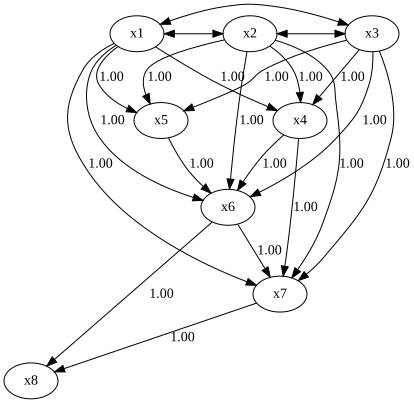

Rank 2: BP=0.099; ave: AU=0.616 SI=0.000, best: AU=0.659 SI=0.000, poly1: AU=0.107 SI=0.000


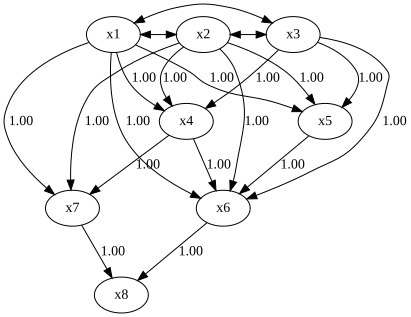

Rank 3: BP=0.089; ave: AU=0.677 SI=0.000, best: AU=0.649 SI=0.000, poly1: AU=0.104 SI=0.000


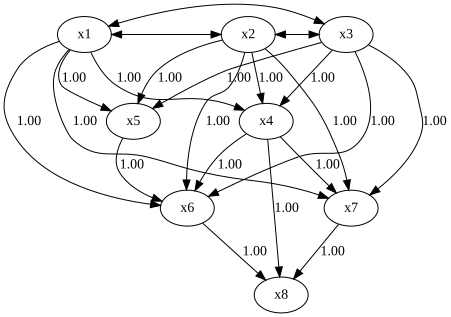

Rank 4: BP=0.005; ave: AU=0.683 SI=0.000, best: AU=0.632 SI=0.000, poly1: AU=0.007 SI=0.000


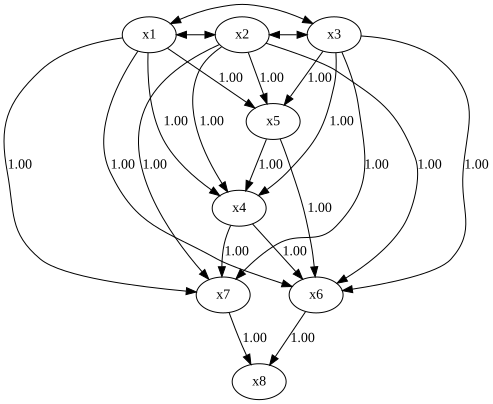

Rank 5: BP=0.003; ave: AU=0.574 SI=0.000, best: AU=0.623 SI=0.000, poly1: AU=0.002 SI=0.000


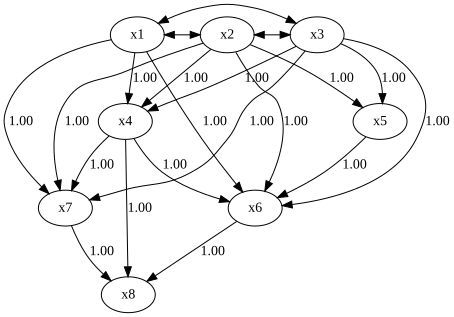

Condition: poly1


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
5,graph:646d6309d2d788ff812ca2531750d83bcbe93a16,0.570,0.565034,0.150695,0.621569,0.190879,0.561965,0.12393
1,graph:6af82e21d4aa9bb0fd8e7e240177efd72a479446,0.099,0.616230,0.000000,0.659349,0.000000,0.106629,0.00000
2,graph:6a4c141e2b81a4d7961b587b46bfece2ddae04ee,0.089,0.677037,0.000000,0.648673,0.000000,0.104438,0.00000
35,graph:7ed498a4afcbedaed098823b628efe3d8d6cbb54,0.044,0.239533,0.000000,0.095644,0.000000,0.035009,0.00000
11,graph:2557f0530bb4a8994231b50f7a6cafb8a2b8f524,0.026,0.302974,0.000000,0.368666,0.000000,0.022504,0.00000


Rank 1: BP=0.570; ave: AU=0.565 SI=0.151, best: AU=0.622 SI=0.191, poly1: AU=0.562 SI=0.124


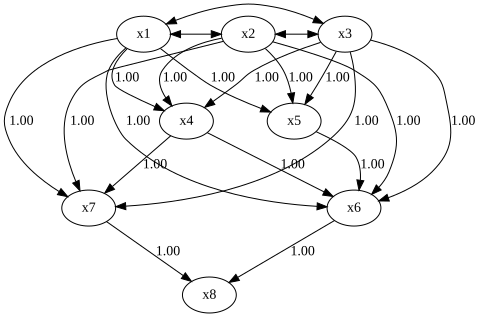

Rank 2: BP=0.099; ave: AU=0.616 SI=0.000, best: AU=0.659 SI=0.000, poly1: AU=0.107 SI=0.000


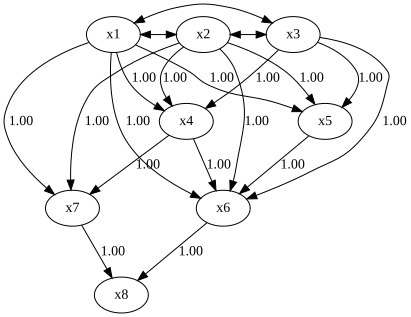

Rank 3: BP=0.089; ave: AU=0.677 SI=0.000, best: AU=0.649 SI=0.000, poly1: AU=0.104 SI=0.000


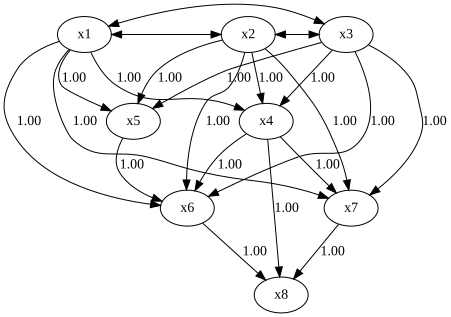

Rank 4: BP=0.044; ave: AU=0.240 SI=0.000, best: AU=0.096 SI=0.000, poly1: AU=0.035 SI=0.000


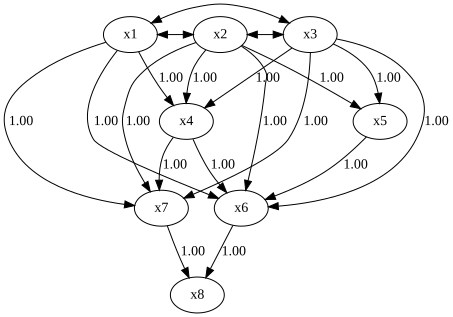

Rank 5: BP=0.026; ave: AU=0.303 SI=0.000, best: AU=0.369 SI=0.000, poly1: AU=0.023 SI=0.000


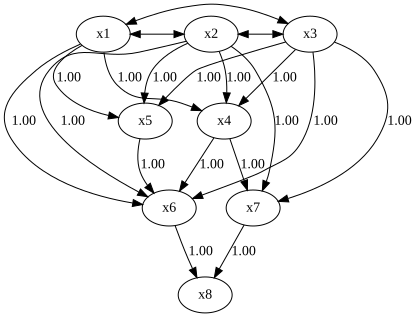

In [25]:
def draw_graph(graph_id):
    state = graph_states[graph_id]
    adjacency = state.astype(float)
    adjacency[state == 2] = np.nan  # bidirected edge
    return make_dot(adjacency, labels=variable_names)


TOP_GRAPH_COUNT = 5

for condition in conditions:
    top_graph_rows = graph_comparison.sort_values(
        [f"au_pvalue_{condition}", "bp_at_sa1", "hypothesis_id"], ascending=[False, False, True]
    ).head(TOP_GRAPH_COUNT)
    print(f"Condition: {condition}")
    display(top_graph_rows)

    for rank, (_, row) in enumerate(top_graph_rows.iterrows(), start=1):
        pvalues = ", ".join(
            f"{c}: AU={row[f'au_pvalue_{c}']:.3f} SI={row[f'si_pvalue_{c}']:.3f}"
            for c in conditions
        )
        print(f"Rank {rank}: BP={row['bp_at_sa1']:.3f}; {pvalues}")
        display(draw_graph(row["hypothesis_id"]))